# Evaluation Environment Setup

In [1]:
import os
import sys
import json
import random
import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from pathlib import Path

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [3]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "celeba" / "processed"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

TEST_CSV = DATA_DIR / "test.csv"

CHECKPOINT_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"

assert TEST_CSV.exists(), "Test CSV not found!"
assert CHECKPOINT_PATH.exists(), "Latest checkpoint not found!" 

# Load the Trained MobileFaceNet Model.

In [4]:
sys.path.insert(0, str(PROJECT_ROOT))

from src.model import FaceRecognitionModel

In [5]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

NUM_CLASSES = len(checkpoint["identity_to_class"])
EMBEDDING_SIZE = 128

model = FaceRecognitionModel(
    embedding_size=EMBEDDING_SIZE,
    num_classes=NUM_CLASSES
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

print("Completed Epochs:", checkpoint["completed_epoch"])
print("Global Steps:", checkpoint["global_step"])
print("Number of Classes:", NUM_CLASSES)
print("Embedding Dimension:", EMBEDDING_SIZE)

Completed Epochs: 20
Global Steps: 54780
Number of Classes: 5103
Embedding Dimension: 128


In [6]:
dummy_input = torch.randn(2, 3, 112, 112).to(DEVICE)

with torch.inference_mode():
    embeddings = model(dummy_input)

print("Input Shape:", dummy_input.shape)
print("Embedding Shape:", embeddings.shape)
print("Embeddings Normalized:", torch.allclose(
    F.normalize(embeddings, p=2, dim=1),
    embeddings,
    atol=1e-5
))

Input Shape: torch.Size([2, 3, 112, 112])
Embedding Shape: torch.Size([2, 128])
Embeddings Normalized: False


# Test Dataset Preparation

In [7]:
test_df = pd.read_csv(TEST_CSV)

print("Test Dataset")
print("Images:", len(test_df))
print("Identities:", test_df["identity_id"].nunique())

Test Dataset
Images: 19962
Identities: 1000


In [8]:
test_identity_counts = test_df["identity_id"].value_counts()

print("Test Identity Image Counts:")
print(test_identity_counts.describe())

Test Identity Image Counts:
count    1000.000000
mean       19.962000
std         8.985282
min         1.000000
25%        13.000000
50%        21.000000
75%        30.000000
max        32.000000
Name: count, dtype: float64


# Generate Verification Pairs

In [9]:
def get_identity_groups(dataframe):

    identity_groups = {}

    for identity_id, indices in dataframe.groupby("identity_id").indices.items():

        if len(indices) >= 2:
            identity_groups[identity_id] = indices

    return identity_groups


test_identity_groups = get_identity_groups(test_df)

print("Test Eligible Identities:", len(test_identity_groups))

Test Eligible Identities: 997


In [10]:
def generate_verification_pairs(
    identity_groups,
    pairs_per_identity=5,
    seed=42
):

    rng = np.random.default_rng(seed)

    genuine_pairs = set()
    impostor_pairs = set()

    identity_ids = list(identity_groups.keys())

    # --------------------------------
    # 1. Generate Genuine Pairs
    # --------------------------------

    for identity_id, indices in identity_groups.items():

        possible_pairs = [
            (int(indices[i]), int(indices[j]))
            for i in range(len(indices))
            for j in range(i + 1, len(indices))
        ]

        number_of_pairs = min(
            pairs_per_identity,
            len(possible_pairs)
        )

        selected_indices = rng.choice(
            len(possible_pairs),
            size=number_of_pairs,
            replace=False
        )

        for index in selected_indices:
            genuine_pairs.add(possible_pairs[index])

    # --------------------------------
    # 2. Generate Impostor Pairs
    # --------------------------------

    target_count = len(genuine_pairs)

    while len(impostor_pairs) < target_count:

        identity_a, identity_b = rng.choice(
            identity_ids,
            size=2,
            replace=False
        )

        image_a = int(rng.choice(identity_groups[identity_a]))
        image_b = int(rng.choice(identity_groups[identity_b]))

        pair = tuple(sorted((image_a, image_b)))

        if pair not in genuine_pairs:
            impostor_pairs.add(pair)

    # --------------------------------
    # 3. Combine Pairs and Labels
    # --------------------------------

    pairs = list(genuine_pairs) + list(impostor_pairs)

    labels = (
        [1] * len(genuine_pairs) +
        [0] * len(impostor_pairs)
    )

    # Shuffle pairs and corresponding labels
    shuffle_indices = rng.permutation(len(pairs))

    pairs = np.asarray(pairs)[shuffle_indices]
    labels = np.asarray(labels)[shuffle_indices]

    return pairs, labels

In [11]:
PAIRS_PER_IDENTITY = 5

test_pairs, test_pair_labels = generate_verification_pairs(
    identity_groups=test_identity_groups,
    pairs_per_identity=PAIRS_PER_IDENTITY,
    seed=42
)

print("\nTEST VERIFICATION DATA")
print("-" * 35)
print("Total Pairs:", len(test_pairs))
print("Genuine Pairs:", np.sum(test_pair_labels == 1))
print("Impostor Pairs:", np.sum(test_pair_labels == 0))


TEST VERIFICATION DATA
-----------------------------------
Total Pairs: 9670
Genuine Pairs: 4835
Impostor Pairs: 4835


# Facial Embedding Extraction

In [12]:
from src.dataset import CelebADataset
from src.transforms import get_eval_transforms

BATCH_SIZE = 32

eval_transform = get_eval_transforms(image_size=112)

# Create test dataset
test_dataset = CelebADataset(
    dataframe=test_df,
    transform=eval_transform
)

# Create DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("TEST EVALUATION DATASET")
print("-" * 40)
print(f"Test Images:  {len(test_dataset):,}")
print(f"Batch Size:   {BATCH_SIZE}")
print(f"Test Batches: {len(test_loader):,}")

TEST EVALUATION DATASET
----------------------------------------
Test Images:  19,962
Batch Size:   32
Test Batches: 624


In [13]:
def extract_embeddings(model, dataloader, device):

    model.eval()

    all_embeddings = []
    all_labels = []

    with torch.inference_mode():

        for images, labels in tqdm(
            dataloader,
            desc="Extracting Embeddings"
        ):

            images = images.to(device, non_blocking=True)

            # Forward pass through MobileFaceNet
            embeddings = model(images)

            # L2 normalization
            embeddings = F.normalize(
                embeddings,
                p=2,
                dim=1
            )

            all_embeddings.append(
                embeddings.cpu()
            )

            all_labels.append(
                labels.cpu()
            )

    # Combine all batches
    all_embeddings = torch.cat(all_embeddings, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    return all_embeddings, all_labels

In [14]:
test_embeddings, test_labels = extract_embeddings(
    model,
    test_loader,
    DEVICE
)

print("\nEMBEDDING EXTRACTION COMPLETE")
print("-" * 45)

print(f"Test Embeddings: {test_embeddings.shape}")

# Check L2 normalization
test_norms = test_embeddings.norm(p=2, dim=1)

test_normalized = torch.allclose(
    test_norms,
    torch.ones_like(test_norms),
    atol=1e-5
)

print(f"Test Normalized: {test_normalized}")

Extracting Embeddings:   0%|          | 0/624 [00:00<?, ?it/s]


EMBEDDING EXTRACTION COMPLETE
---------------------------------------------
Test Embeddings: torch.Size([19962, 128])
Test Normalized: True


# Cosine Similarity Calculation

In [15]:
def calculate_pair_similarity(embeddings, pairs):

    pairs = torch.as_tensor(
        pairs,
        dtype=torch.long
    )

    # Select the two embeddings for every pair
    embedding_1 = embeddings[pairs[:, 0]]
    embedding_2 = embeddings[pairs[:, 1]]

    # Cosine similarity (embeddings are already normalized)
    similarities = torch.sum(
        embedding_1 * embedding_2,
        dim=1
    )

    return similarities.numpy()


test_scores = calculate_pair_similarity(
    test_embeddings,
    test_pairs
)

test_pair_labels = np.asarray(test_pair_labels)

print("COSINE SIMILARITY CALCULATION")
print("-" * 45)

print(f"Test Scores: {test_scores.shape}")
print(f"Test Range: {test_scores.min():.4f} to {test_scores.max():.4f}")

print("\nPair and Label Alignment")
print("Test:", len(test_scores) == len(test_pair_labels))

COSINE SIMILARITY CALCULATION
---------------------------------------------
Test Scores: (9670,)
Test Range: 0.8881 to 0.9997

Pair and Label Alignment
Test: True


# Similarity Score Analysis

In [16]:
# Separate test scores
test_genuine_scores = test_scores[
    test_pair_labels == 1
]

test_impostor_scores = test_scores[
    test_pair_labels == 0
]


# Statistical summary function
def display_score_statistics(name, scores):

    print(f"\n{name}")
    print("-" * 40)
    print(f"Count:  {len(scores)}")
    print(f"Mean:   {np.mean(scores):.4f}")
    print(f"Std:    {np.std(scores):.4f}")
    print(f"Min:    {np.min(scores):.4f}")
    print(f"Max:    {np.max(scores):.4f}")


print("TEST SCORE ANALYSIS")
print("=" * 45)

display_score_statistics(
    "Genuine Pairs",
    test_genuine_scores
)

display_score_statistics(
    "Impostor Pairs",
    test_impostor_scores
)

TEST SCORE ANALYSIS

Genuine Pairs
----------------------------------------
Count:  4835
Mean:   0.9738
Std:    0.0158
Min:    0.9020
Max:    0.9997

Impostor Pairs
----------------------------------------
Count:  4835
Mean:   0.9298
Std:    0.0126
Min:    0.8881
Max:    0.9910


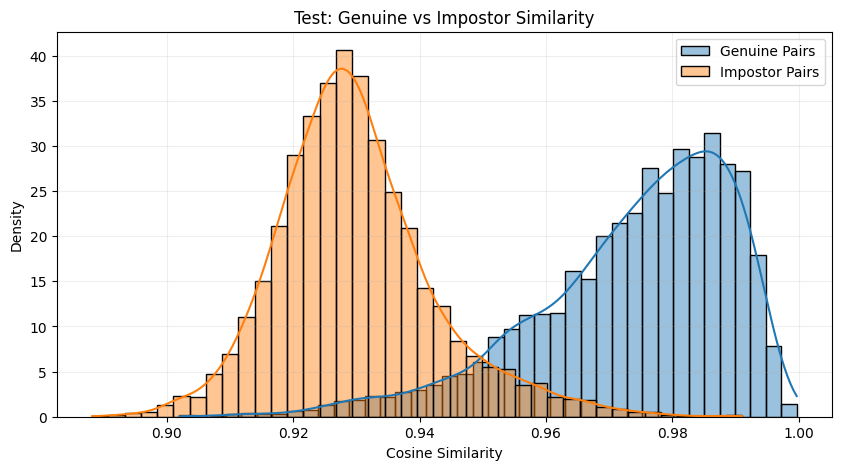

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    test_genuine_scores,
    bins=40,
    kde=True,
    stat="density",
    label="Genuine Pairs",
    alpha=0.45
)

sns.histplot(
    test_impostor_scores,
    bins=40,
    kde=True,
    stat="density",
    label="Impostor Pairs",
    alpha=0.45
)

plt.title("Test: Genuine vs Impostor Similarity")
plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Verification Performance Metrics

In [18]:
test_fpr, test_tpr, test_thresholds = roc_curve(
    test_pair_labels,
    test_scores
)

test_auc = roc_auc_score(
    test_pair_labels,
    test_scores
)

print("ROC-AUC RESULTS")
print("-" * 40)
print(f"Test ROC-AUC: {test_auc:.4f}")

ROC-AUC RESULTS
----------------------------------------
Test ROC-AUC: 0.9701


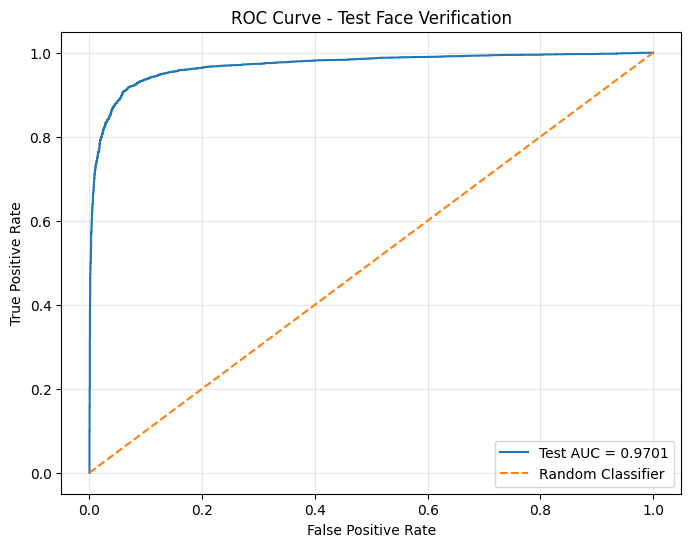

In [19]:
plt.figure(figsize=(8, 6))

plt.plot(
    test_fpr,
    test_tpr,
    label=f"Test AUC = {test_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Test Face Verification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
test_far = test_fpr
test_frr = 1 - test_tpr

# Calculate Equal Error Rate
eer = brentq(
    lambda x: 1. - x - interp1d(
        test_fpr,
        test_tpr
    )(x),
    0.0,
    1.0
)

eer_threshold = interp1d(
    test_fpr,
    test_thresholds
)(eer)

print("EQUAL ERROR RATE")
print("-" * 40)
print(f"EER:       {eer:.4f}")
print(f"EER (%):   {eer * 100:.2f}%")
print(f"Threshold: {float(eer_threshold):.4f}")

EQUAL ERROR RATE
----------------------------------------
EER:       0.0784
EER (%):   7.84%
Threshold: 0.9489


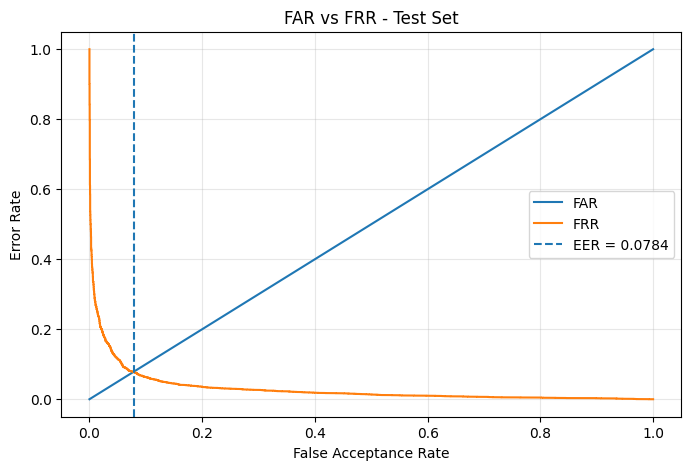

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    test_fpr,
    test_far,
    label="FAR"
)

plt.plot(
    test_fpr,
    test_frr,
    label="FRR"
)

plt.axvline(
    eer,
    linestyle="--",
    label=f"EER = {eer:.4f}"
)

plt.xlabel("False Acceptance Rate")
plt.ylabel("Error Rate")
plt.title("FAR vs FRR - Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Exploratory Threshold Evaluation

The following cell applies the EER threshold to the same test pairs used to derive it. Treat these metrics as in-sample descriptive results, not an unbiased final test estimate.

In [22]:
# Apply EER threshold
test_predictions = (
    test_scores >= float(eer_threshold)
).astype(int)

test_accuracy = accuracy_score(
    test_pair_labels,
    test_predictions
)

test_confusion = confusion_matrix(
    test_pair_labels,
    test_predictions
)

tn, fp, fn, tp = test_confusion.ravel()

test_far_at_threshold = fp / (fp + tn)
test_frr_at_threshold = fn / (fn + tp)

print("TEST THRESHOLD RESULTS (EXPLORATORY)")
print("-" * 45)
print(f"Threshold: {float(eer_threshold):.4f}")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"FAR:       {test_far_at_threshold:.4f}")
print(f"FRR:       {test_frr_at_threshold:.4f}")

print("\nConfusion Matrix")
print(test_confusion)

TEST THRESHOLD RESULTS (EXPLORATORY)
---------------------------------------------
Threshold: 0.9489
Accuracy:  0.9217
FAR:       0.0782
FRR:       0.0784

Confusion Matrix
[[4457  378]
 [ 379 4456]]


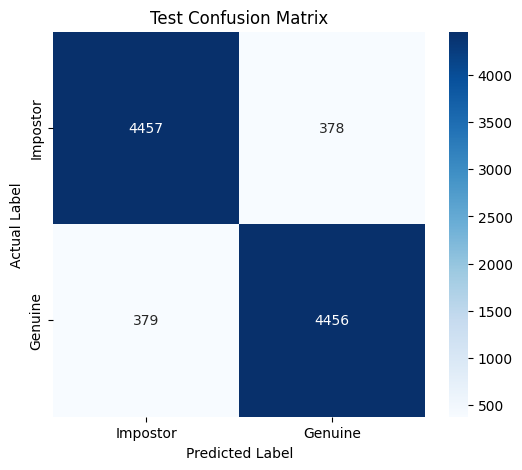

In [23]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    test_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Impostor", "Genuine"],
    yticklabels=["Impostor", "Genuine"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Test Confusion Matrix")
plt.show()

# Save Evaluation Results

In [25]:
RESULTS_DIR = DATA_DIR / "verification_evaluation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Save evaluation summary
evaluation_results = {
    "evaluation_split": "test",
    "evaluation_note": "Exploratory test-only evaluation. EER threshold was derived from these same test pairs.",
    "total_pairs": int(len(test_pairs)),
    "genuine_pairs": int(np.sum(test_pair_labels == 1)),
    "impostor_pairs": int(np.sum(test_pair_labels == 0)),
    "roc_auc": float(test_auc),
    "eer": float(eer),
    "eer_threshold": float(eer_threshold),
    "accuracy_at_eer_threshold": float(test_accuracy),
    "far_at_eer_threshold": float(test_far_at_threshold),
    "frr_at_eer_threshold": float(test_frr_at_threshold)
}

with open(RESULTS_DIR / "evaluation_results.json", "w") as file:
    json.dump(evaluation_results, file, indent=4)

print("Evaluation results saved to:", RESULTS_DIR)

Evaluation results saved to: Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\processed\verification_evaluation
